# 🍷 Exploring the Wine Recognition Dataset with Pandas & Seaborn

The Wine Recognition Dataset contains the results of chemical analysis of wines grown in Italy. The dataset consists of three different wine cultivars:

- **Class 0**
- **Class 1**
- **Class 2**

It contains 178 wine samples, each described using 13 continuous chemical attributes:

1. Alcohol
2. Malic acid
3. Ash
4. Alcalinity of ash
5. Magnesium
6. Total phenols
7. Flavanoids
8. Nonflavanoid phenols
9. Proanthocyanins
10. Color intensity
11. Hue
12. OD280/OD315 of diluted wines
13. Proline

The objective of this notebook is to explore the dataset, understand the chemical attributes, visualize patterns among the three cultivars, and prepare the data for Machine Learning.

In [10]:
# Import foundational libraries for data manipulation, visualization, and ML
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

# Set visualization theme
sns.set_theme(style="whitegrid")

## 1. Loading the Dataset as a DataFrame

Load the dataset from `sklearn.datasets` with `as_frame=True` to immediately obtain a structured `pandas.DataFrame`.

In [11]:
# Load the wine dataset directly as a DataFrame
wine_data = load_wine(as_frame=True)
df = wine_data.frame

# Inspect the first 5 records
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [12]:
# Check dataset structure, data types, and verify zero missing values
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

## 2. Summary Statistics & Class Balance

In [13]:
# Generate summary statistics (mean, standard deviation, min, max, quartiles)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


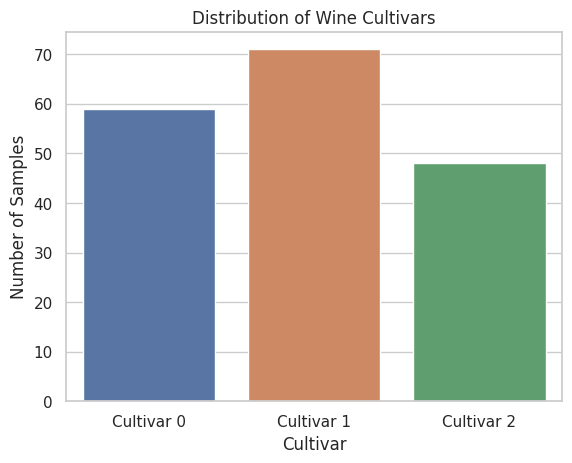

In [14]:
# Map target numbers to human-readable cultivator names and inspect distribution
cultivar_map = {0: 'Cultivar 0', 1: 'Cultivar 1', 2: 'Cultivar 2'}
df['cultivar'] = df['target'].map(cultivar_map)

sns.countplot(data=df, x='cultivar', hue='cultivar', legend=False)

plt.title("Distribution of Wine Cultivars")
plt.xlabel("Cultivar")
plt.ylabel("Number of Samples")
plt.show()

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the relationships and distributions of different chemical attributes.

Four features — Alcohol, Flavanoids, Color Intensity, and Proline — are selected for visualization to explore how their values vary across the three wine cultivars.

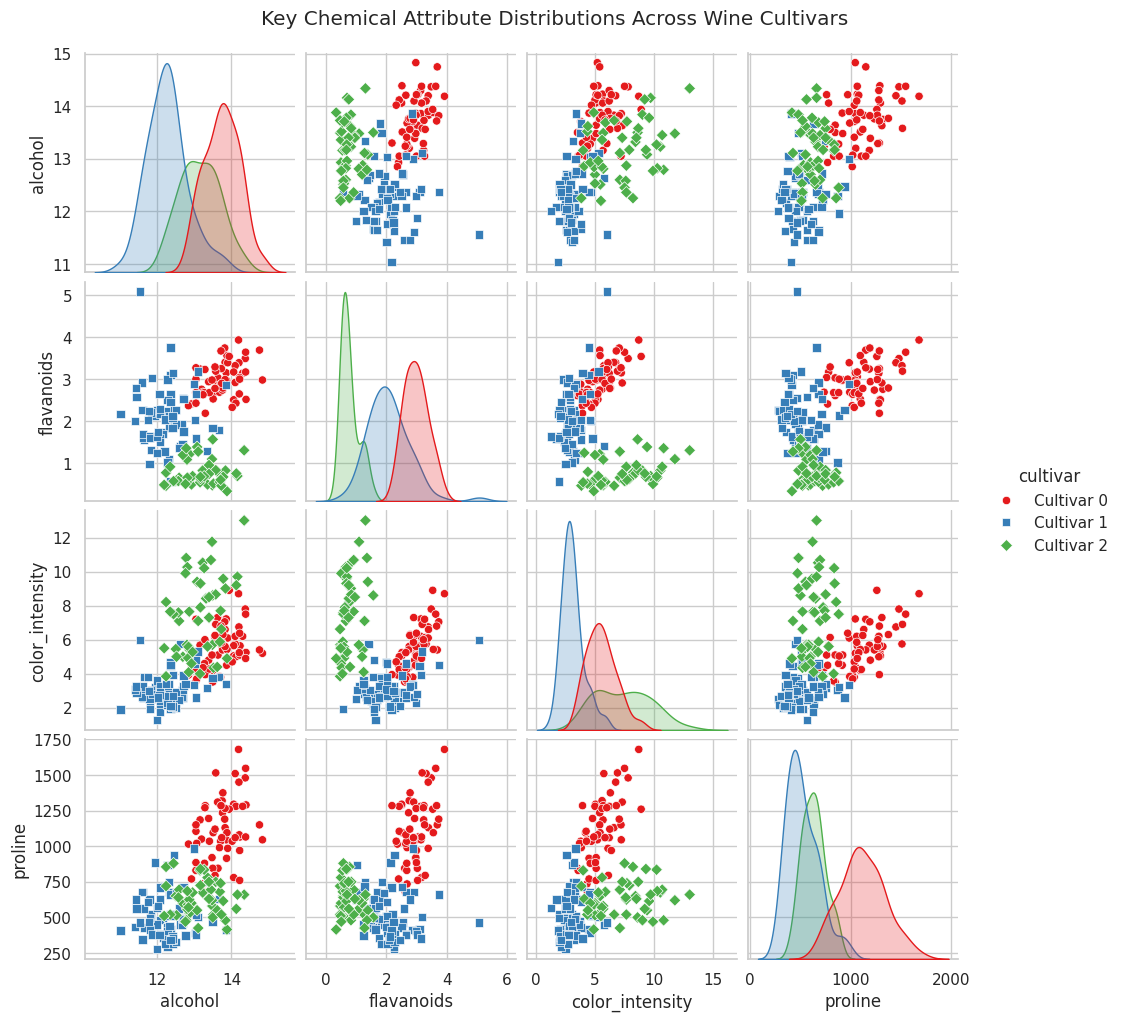

In [15]:
# Pairplot on a select subset of distinctive chemical features
selected_features = ['alcohol', 'flavanoids', 'color_intensity', 'proline']
sns.pairplot(df[selected_features + ['cultivar']], hue='cultivar', palette='Set1', markers=['o', 's', 'D'])
plt.suptitle("Key Chemical Attribute Distributions Across Wine Cultivars", y=1.02)
plt.show()

### Observation

The pairplot illustrates the distributions and relationships between selected chemical attributes across the three wine cultivars. Some features show visible differences in their distributions, suggesting that chemical characteristics can help distinguish between wine cultivars.

## 4. Preparing Data for Machine Learning

Before applying Machine Learning algorithms, the dataset is separated into two parts:

- **Feature Matrix (X):** Contains the 13 numerical chemical attributes used as input features.
- **Target Vector (y):** Contains the corresponding wine cultivar labels (0, 1, 2), which represent the output classes.

These two components are prepared separately for model training and evaluation.

In [16]:
# Extract feature matrix X and target vector y as NumPy arrays
X = wine_data.data.to_numpy()
y = wine_data.target.to_numpy()

# Verify types and dimensions
print(f"X type: {type(X)}, Shape: {X.shape}")
print(f"y type: {type(y)}, Shape: {y.shape}")

X type: <class 'numpy.ndarray'>, Shape: (178, 13)
y type: <class 'numpy.ndarray'>, Shape: (178,)


## 5. Train / Test Split

Evaluate model performance on unseen data by splitting into training (80%) and test (20%) sets using stratified sampling to preserve cultivar class ratios.

In [17]:
from sklearn.model_selection import train_test_split

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")

Training samples: 142
Testing samples:  36


## 6. Conclusion

In this notebook, the Wine Recognition Dataset was explored using Pandas and Seaborn. The dataset contains 178 samples, 13 chemical attributes, and three wine cultivar classes.

Exploratory Data Analysis helped understand the distribution of chemical properties and identify patterns among the cultivars. The dataset was then separated into feature and target variables and divided into training and testing sets using stratified sampling.

The prepared dataset is now ready for applying supervised Machine Learning classification algorithms in the next notebook.